In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import axes3d
from mpl_toolkits import mplot3d


\begin{align}
\frac{\partial u}{\partial t}\left(x,y\right)\:=\:\alpha^2\cdot \frac{\partial u}{\partial x^2}\left(x,y\right)
\end{align}
# Método Explícito
\begin{align}
\frac{u_i^{k+1}−\:u_i^k}{h_t}=\:D\frac{ u_{i+1}^{k}\:−\:2u_i^k\:+\:u_{i-1}^{k}}{h_x^2}
\end{align}
\begin{align}
u_i^{k+1}\:=\:u_i^k\:+\:D\frac{h_t}{h_x^2}( u_{i+1}^{k}\:−\:2u_i^k\:+\:u_{i-1}^{k})
\end{align}
# Método Implícito
\begin{align}
\left(1\:+\:2D\frac{h_t}{h_x^2}\right)u_i^k\:−\:D\frac{h_t}{h_x^2}u_{i+1}^{k}\:+\:u_{i-1}^{k}=\:u_i^{k−1}
\end{align}

In [ ]:
def g(x):
    return np.sin(x*(np.pi)/2)
def fa(x,t):
    return 0
def fb(x,t):
    return 0

def f(x,t):  # termo fonte da equação = 0
    return 0

# metodo explicito

In [ ]:
D=1
a=0
b=2
T=2
hx=0.05  #  -> l = 2 m = 4   -> l/m
ht=0.001 #  -> T = 0.1 N = 2  -> T/N

Condicao de convergencia satisfeita!


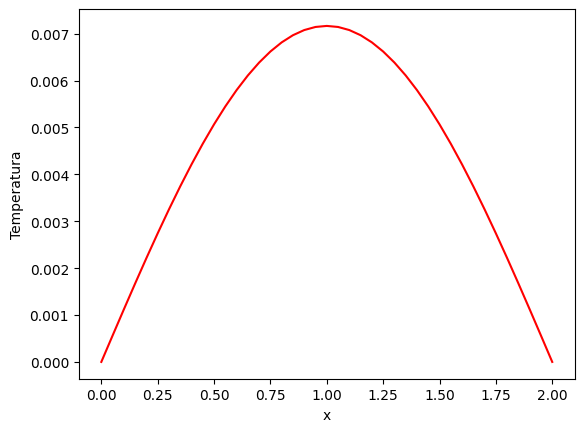

In [ ]:
#def explicito_calor(fa,fb,g,D,a,b,T,hx,ht):
if((D*ht)/(hx**2) <= 0.5):
    print('Condicao de convergencia satisfeita!')
else:
    print('Condicao de convergencia NAO satisfeita!')

nx=round((b-a)/hx)
nt=round(T/ht)

lx = np.arange(a,b+hx,hx)
lt = np.arange(0,T+ht,ht)
u = np.zeros((nt+1, nx+1))


#condicao inicial
u[0,:] = g(lx)

#condicao fronteira
u[:,0] = fa(lx,lt)
u[:, -1] = fb(lx,lt)

#Iteracoes
for kk in range(0,nt):
    for ii in range(1,nx):
        u[kk+1,ii] = u[kk,ii] + ht*((D*(u[kk,ii+1]-2*u[kk,ii]+u[kk,ii-1]))/(hx**2) + f(lx[ii],lt[kk]))
        #print(lx[ii])
    #u[kk+1,ii] =

#print(nx)
plt.plot(lx,u[-1,:],'r-')
plt.xlabel('x');
plt.ylabel('Temperatura');
plt.show()
#return u

In [ ]:
# solução analitica
s = np.zeros((nt+1, nx+1))
for kk in range(0,nt+1):
    for ii in range(0,nx+1):
        s[kk,ii] = np.exp(-((np.pi*np.pi)/4)*lt[kk])*np.sin((np.pi*lx[ii])/2)


In [ ]:
# erro maximo absoluto no tempo = 2
max(abs(s[-1,:]-u[-1,:]))

2.5526455095327416e-05

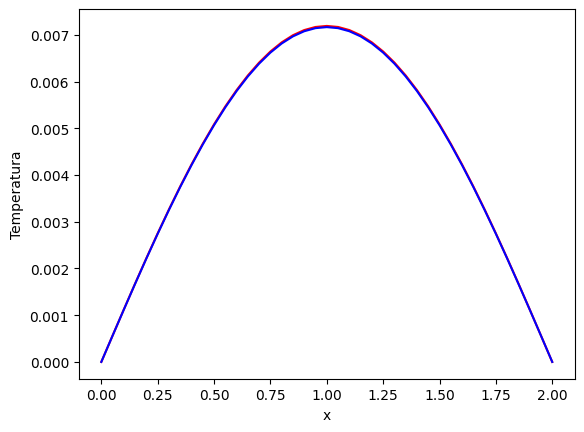

In [ ]:
# grafico da solução analitica e da solução numérica no tempo = 2
plt.plot(lx,s[-1,:],'r-')
plt.plot(lx,u[-1,:],'b-')
plt.xlabel('x');
plt.ylabel('Temperatura');
plt.show()

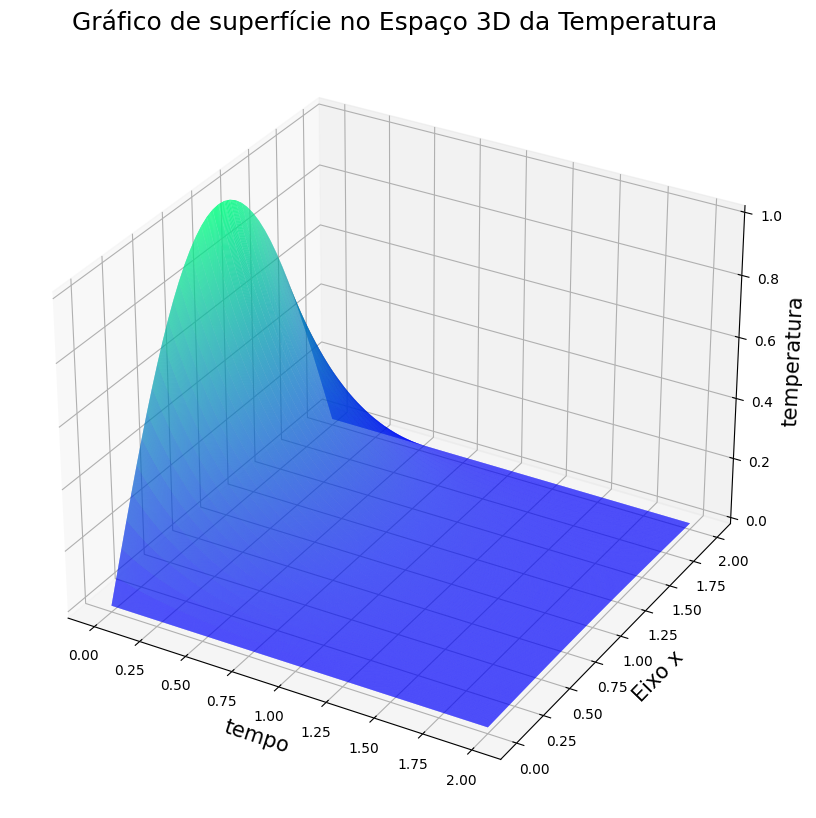

In [ ]:
x, t = np.meshgrid(lx, lt)
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection='3d')
ax.contour3D(t,x,u, 50, cmap='binary')
ax = plt.axes(projection='3d')
ax.plot_surface(t,x,u, rstride=1, cstride=1,cmap='winter', edgecolor='none')
ax.set_title('Gráfico de superfície no Espaço 3D da Temperatura', fontsize=18);
ax.set_xlabel('tempo', fontsize=15)
ax.set_ylabel('Eixo x', fontsize=15)
ax.set_zlabel('temperatura', fontsize=15)
#ax.view_init(60, 45)
plt.show()


# a temperatura decai com o tempo conforme apresentado no grafico acima.

# Metodo implicito

In [ ]:
D=1
a=0
b=2
T=2
hx=0.05  #  -> l = 2 m = 4   -> l/m
ht=0.005 # -> T = 0.1 N = 2  -> T/N

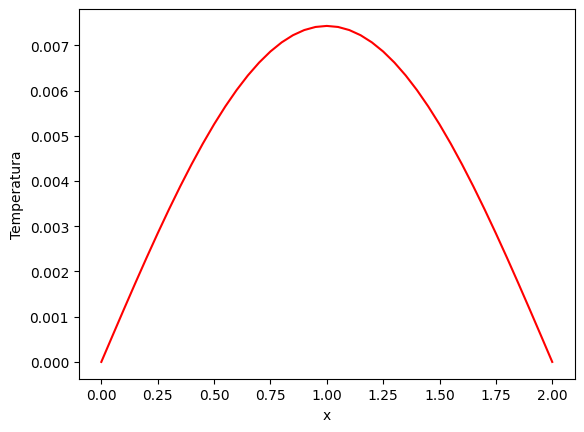

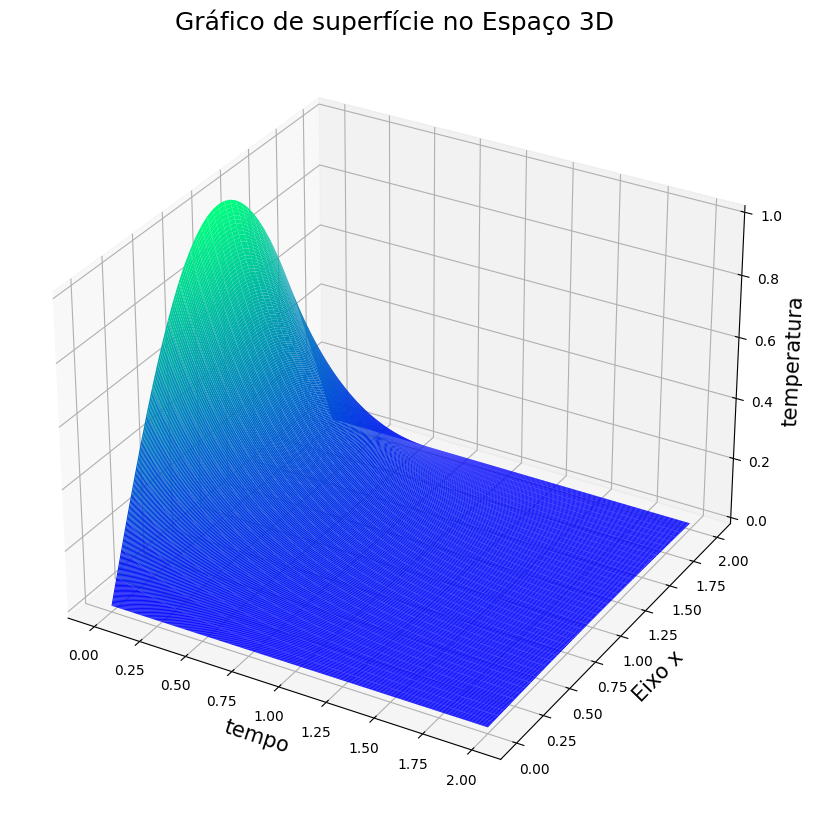

In [ ]:
nx=round((b-a)/hx)
nt=round(T/ht)

lx = np.arange(a,b+hx,hx)
lt = np.arange(0,T+ht,ht)
u = np.zeros((nt+1, nx+1))

#condicao inicial
u[0,:] = g(lx)

#condicao fronteira
u[:,0]=fa(lx,lt)
u[:,-1]=fb(lx,lt)

b = np.zeros((nx-1, 1))
A = (1+((2*D*ht)/(hx**2)))*np.eye(nx-1)
for ii in range(nx-2):
    A[ii,ii+1] = -(D*ht)/(hx**2)
    A[ii+1,ii] = -(D*ht)/(hx**2)
#Iteracoes

for kk in range(0, nt):

    #for ii in range(1, nx-1):
    #    b[ii,0] = ((u[kk,ii])  +f(lx[ii],lt[kk])*ht).T
    b = (u[kk,1:nx]) + f(lx[1:nx],lt[kk])*ht


    b[0]= b[0]+(u[kk+1,0]*(D*ht)/(hx*2)) + f(lx[0],lt[kk])*ht
    b[-1]= b[-1]+(u[kk+1,-1]*(D*ht)/(hx*2)) + f(lx[-1],lt[kk])*ht
    #print(b[-1], (u[kk+1,0]*(D*ht)/(hx*2)))
    u[kk+1,1:nx] = np.linalg.solve(A, b)




plt.plot(lx,u[-1,:],'r-')
plt.xlabel('x');
plt.ylabel('Temperatura');
plt.show()

x, t = np.meshgrid(lx, lt)
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection='3d')
ax.contour3D(t,x,u, 50, cmap='binary')
ax = plt.axes(projection='3d')
ax.plot_surface(t,x,u, rstride=1, cstride=1,cmap='winter', edgecolor='none')
ax.set_title('Gráfico de superfície no Espaço 3D', fontsize=18);
ax.set_xlabel('tempo', fontsize=15)
ax.set_ylabel('Eixo x', fontsize=15)
ax.set_zlabel('temperatura', fontsize=15)
#ax.view_init(60, 45)
plt.show()


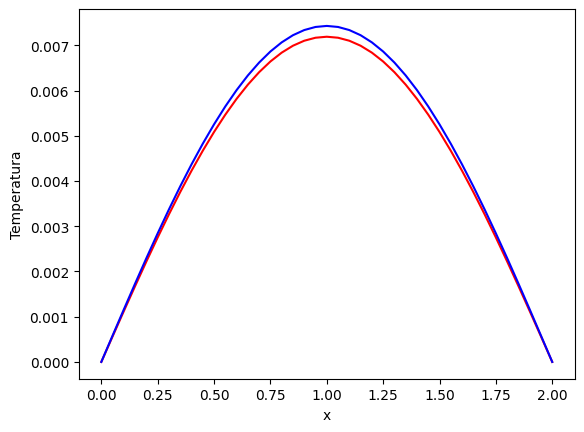

In [ ]:
# grafico da solução analitica e da solução numérica no tempo = 2
plt.plot(lx,s[-1,:],'r-')
plt.plot(lx,u[-1,:],'b-')
plt.xlabel('x')
plt.ylabel('Temperatura')
plt.show()

In [ ]:
# erro maximo absoluto no tempo = 2
max(abs(s[-1,:]-u[-1,:]))

0.000239043718629749

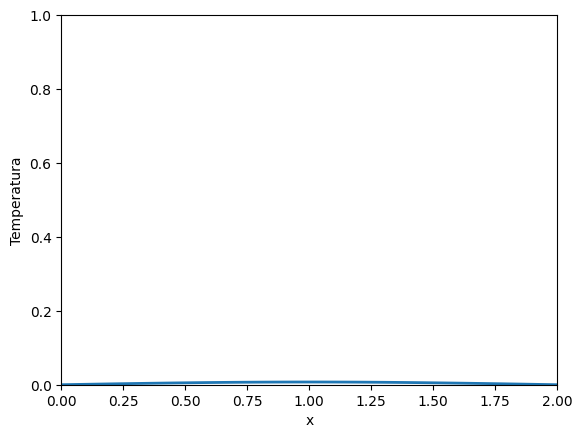

In [ ]:
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure()

axis = plt.axes(xlim =(0, 2),
                ylim =(0, 1))
plt.xlabel('x')
plt.ylabel('Temperatura')
line, = axis.plot([], [], lw = 2)

# what will our line dataset
# contain?
def init():
    line.set_data([], [])
    return line,

# initializing empty values
# for x and y co-ordinates
xdata, ydata = [], []

# animation function
def animate(i):

    line.set_data(lx, u[i*10,:])

    return line,

# calling the animation function
anim = animation.FuncAnimation(fig, animate,
                            init_func = init,
                            frames = 200,
                            interval = 20,
                            blit = True)

# saves the animation in our desktop
anim.save('grafico_animado.gif', writer = 'ffmpeg', fps = 30)